# Setup & Load Untouched Raw Data (Kaggle CSV)

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    classification_report, precision_recall_curve
)
from xgboost import XGBClassifier
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Anchor working directory to day-13-employee-attrition/src
PROJECT_SRC = r"C:\Users\adjis\github\100-days-real-world-ml\day-13-employee-attrition\src"
if os.path.exists(PROJECT_SRC):
    os.chdir(PROJECT_SRC)
os.makedirs("outputs", exist_ok=True)

CSV_PATH = "../data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv"
df_raw = pd.read_csv(CSV_PATH)
print(f"Working directory : {os.getcwd()}")
print(f"Raw Dataset Shape : {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
df_raw.head()

C:\Users\adjis\anaconda3\envs\100-days-real-world-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Working directory : C:\Users\adjis\github\100-days-real-world-ml\day-13-employee-attrition\src
Raw Dataset Shape : 1,470 rows, 35 columns


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


# EDA 1: Schema, Duplicates & Zero-Variance Constant Column Audit

In [2]:
print(f"Total Missing Values : {df_raw.isnull().sum().sum()}")
print(f"Exact Duplicate Rows : {df_raw.duplicated().sum()}")

# Audit columns to catch zero-variance constants (nunique == 1) and unique IDs (nunique == len(df))
audit_records = []
for col in df_raw.columns:
    n_uniq = df_raw[col].nunique()
    flag = "OK"
    if n_uniq == 1:
        flag = "ZERO VARIANCE (Drop)"
    elif n_uniq == len(df_raw):
        flag = "UNIQUE ID (Drop)"
    audit_records.append({
        "Column": col,
        "Dtype": str(df_raw[col].dtype),
        "Unique_Values": n_uniq,
        "Audit_Flag": flag,
        "Sample_Values": str(df_raw[col].unique()[:3]),
    })

audit_df = pd.DataFrame(audit_records)
print("Flagged Non-Informative Columns:")
display(audit_df[audit_df["Audit_Flag"] != "OK"])
print(f"\nTotal columns audited: {len(audit_df)} | Flagged for removal: {(audit_df['Audit_Flag'] != 'OK').sum()}")

Total Missing Values : 0
Exact Duplicate Rows : 0
Flagged Non-Informative Columns:


,Column,Dtype,Unique_Values,Audit_Flag,Sample_Values
8,EmployeeCount,int64,1,ZERO VARIANCE (Drop),[1]
9,EmployeeNumber,int64,1470,UNIQUE ID (Drop),[1 2 4]
21,Over18,str,1,ZERO VARIANCE (Drop),"<StringArray>\n['Y']\nLength: 1, dtype: str"
26,StandardHours,int64,1,ZERO VARIANCE (Drop),[80]



Total columns audited: 35 | Flagged for removal: 4


# EDA 2: Target Imbalance, Attrition Drivers (OverTime, JobRole, Income) & Visual Dashboard

Target Variable ('Attrition') Distribution:


,Count,Percentage (%)
Attrition,,
No,1233,83.88
Yes,237,16.12


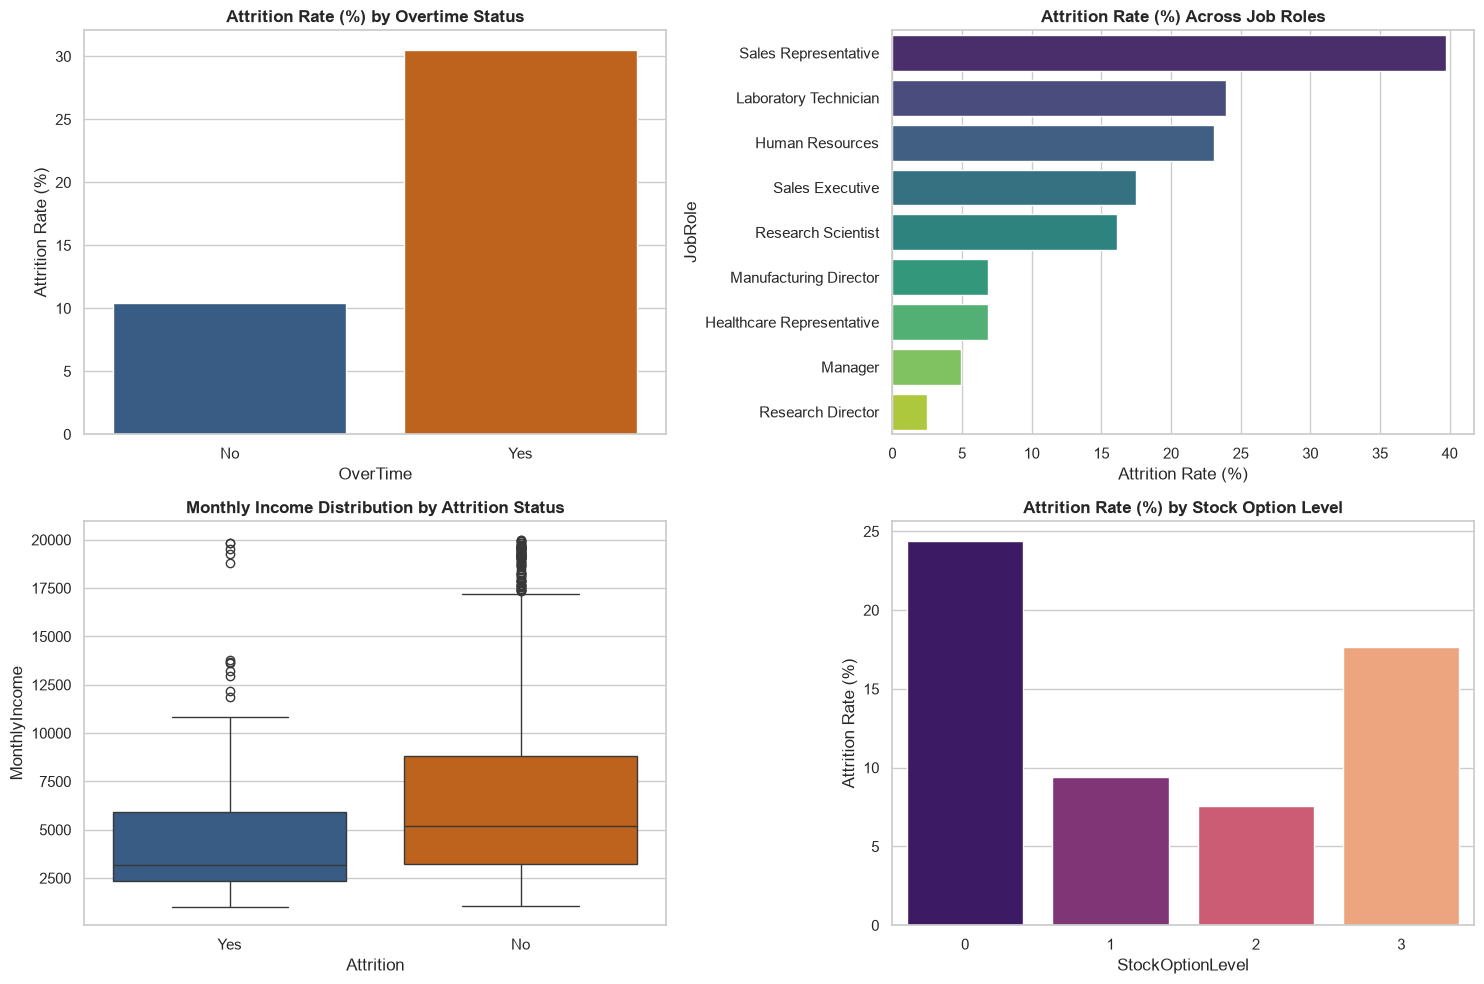

In [3]:
df_eda = df_raw.copy()
df_eda["Attrition_Flag"] = (df_eda["Attrition"] == "Yes").astype(int)

print("Target Variable ('Attrition') Distribution:")
display(pd.DataFrame({
    "Count": df_raw["Attrition"].value_counts(),
    "Percentage (%)": (df_raw["Attrition"].value_counts(normalize=True) * 100).round(2)
}))

# Visual EDA Dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: Attrition Rate by OverTime Status
ot_rate = df_eda.groupby("OverTime")["Attrition_Flag"].mean() * 100
sns.barplot(x=ot_rate.index, y=ot_rate.values, palette=["#2b5c8f", "#d95f02"], ax=axes[0, 0])
axes[0, 0].set_title("Attrition Rate (%) by Overtime Status", fontweight="bold")
axes[0, 0].set_ylabel("Attrition Rate (%)")

# Plot 2: Attrition Rate by JobRole
role_rate = df_eda.groupby("JobRole")["Attrition_Flag"].mean().sort_values(ascending=False) * 100
sns.barplot(x=role_rate.values, y=role_rate.index, palette="viridis", ax=axes[0, 1])
axes[0, 1].set_title("Attrition Rate (%) Across Job Roles", fontweight="bold")
axes[0, 1].set_xlabel("Attrition Rate (%)")

# Plot 3: MonthlyIncome Spread by Attrition
sns.boxplot(data=df_eda, x="Attrition", y="MonthlyIncome", palette=["#2b5c8f", "#d95f02"], ax=axes[1, 0])
axes[1, 0].set_title("Monthly Income Distribution by Attrition Status", fontweight="bold")

# Plot 4: Attrition Rate by Age Bracket & StockOptionLevel
stock_rate = df_eda.groupby("StockOptionLevel")["Attrition_Flag"].mean() * 100
sns.barplot(x=stock_rate.index, y=stock_rate.values, palette="magma", ax=axes[1, 1])
axes[1, 1].set_title("Attrition Rate (%) by Stock Option Level", fontweight="bold")
axes[1, 1].set_ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.savefig("outputs/eda_employee_attrition.png", dpi=150)
plt.show()

# Evidence-Based Data Cleaning

In [4]:
"""
Cleaning Rules Driven by EDA Findings:
1. Drop the 3 zero-variance constant columns ('EmployeeCount', 'StandardHours', 'Over18')
   and the 100% unique primary key ('EmployeeNumber') identified in Cell 2.
2. Convert binary string columns ('Attrition', 'OverTime') cleanly to 0/1 flags.
"""
df_clean = df_raw.copy()

drop_cols = ["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"]
df_clean.drop(columns=drop_cols, inplace=True)

df_clean["Attrition"] = (df_clean["Attrition"] == "Yes").astype(int)
df_clean["OverTime"] = (df_clean["OverTime"] == "Yes").astype(int)

print(f"Dropped columns: {drop_cols}")
print(f"Cleaned Dataset Shape: {df_clean.shape[0]:,} rows, {df_clean.shape[1]} columns | Attrition Rate: {df_clean['Attrition'].mean():.2%}")

Dropped columns: ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber']
Cleaned Dataset Shape: 1,470 rows, 31 columns | Attrition Rate: 16.12%


# HR Domain Feature Engineering & Leak-Free Preprocessing

In [5]:
df_feat = df_clean.copy()

# 1. Compensation competitiveness & promotion stagnation ratios
df_feat["income_per_job_level"] = df_feat["MonthlyIncome"] / df_feat["JobLevel"]
df_feat["years_without_promotion_ratio"] = df_feat["YearsSinceLastPromotion"] / (df_feat["YearsAtCompany"] + 1.0)
df_feat["tenure_stability_ratio"] = df_feat["YearsWithCurrManager"] / (df_feat["YearsAtCompany"] + 1.0)
df_feat["avg_tenure_per_company"] = df_feat["TotalWorkingYears"] / (df_feat["NumCompaniesWorked"] + 1.0)

# 2. Composite satisfaction score & burnout risk interaction (OverTime + Long Commute)
df_feat["overall_satisfaction"] = (
    df_feat["EnvironmentSatisfaction"] + df_feat["JobSatisfaction"] +
    df_feat["RelationshipSatisfaction"] + df_feat["WorkLifeBalance"]
) / 4.0
df_feat["overtime_commute_stress"] = df_feat["OverTime"] * df_feat["DistanceFromHome"]
df_feat["is_early_career_unvested"] = ((df_feat["Age"] <= 30) & (df_feat["StockOptionLevel"] == 0)).astype(int)

X = df_feat.drop(columns=["Attrition"])
y = df_feat["Attrition"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

cat_cols = X_train.select_dtypes(include=["object"]).columns.tolist()
num_cols = [c for c in X_train.columns if c not in cat_cols]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_cols),
])

print(f"Train Set: {X_train.shape} (Positives: {y_train.sum()}) | Test Set: {X_test.shape} (Positives: {y_test.sum()})")

Train Set: (1176, 37) (Positives: 190) | Test Set: (294, 37) (Positives: 47)


# Model Benchmarking (Regularized Logistic Regression vs. Depth-Regularized XGBoost)

In [6]:
def find_optimal_f1_threshold(y_true, y_probs):
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_probs)
    f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-8)
    best_idx = np.argmax(f1_scores[:-1])
    return float(thresholds[best_idx])

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression (L2 Regularized Baseline)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(C=0.2, class_weight="balanced", max_iter=1000, random_state=42)),
    ]),
    "XGBoost (Depth-Regularized HR Engine)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=200,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=5.0,
            min_child_weight=5,
            scale_pos_weight=np.sqrt(scale_pos_weight),
            eval_metric="aucpr",
            random_state=42,
        )),
    ]),
}

best_model, best_cv_auc = None, 0.0

for name, pipeline in models.items():
    cv_roc = cross_val_score(pipeline, X_train, y_train, cv=cv_strategy, scoring="roc_auc").mean()
    cv_pr = cross_val_score(pipeline, X_train, y_train, cv=cv_strategy, scoring="average_precision").mean()

    pipeline.fit(X_train, y_train)
    y_probs = pipeline.predict_proba(X_test)[:, 1]
    opt_thresh = find_optimal_f1_threshold(y_test, y_probs)
    y_pred = (y_probs >= opt_thresh).astype(int)

    test_roc = roc_auc_score(y_test, y_probs)
    test_pr = average_precision_score(y_test, y_probs)

    print(f"\n---> {name}")
    print(f"5-Fold CV : ROC-AUC = {cv_roc:.4f} | PR-AUC = {cv_pr:.4f}")
    print(f"Test Set  : ROC-AUC = {test_roc:.4f} | PR-AUC = {test_pr:.4f} | Optimal Threshold = {opt_thresh:.4f}")
    print(classification_report(y_test, y_pred, target_names=["Stayed (0)", "Attrited (1)"]))

    if cv_roc > best_cv_auc:
        best_cv_auc = cv_roc
        best_model = pipeline

joblib.dump(best_model, "outputs/best_attrition_model.joblib")


---> Logistic Regression (L2 Regularized Baseline)
5-Fold CV : ROC-AUC = 0.8342 | PR-AUC = 0.6355
Test Set  : ROC-AUC = 0.8052 | PR-AUC = 0.5812 | Optimal Threshold = 0.6564
              precision    recall  f1-score   support

  Stayed (0)       0.92      0.91      0.91       247
Attrited (1)       0.55      0.60      0.57        47

    accuracy                           0.86       294
   macro avg       0.74      0.75      0.74       294
weighted avg       0.86      0.86      0.86       294


---> XGBoost (Depth-Regularized HR Engine)
5-Fold CV : ROC-AUC = 0.8227 | PR-AUC = 0.6170
Test Set  : ROC-AUC = 0.7623 | PR-AUC = 0.4945 | Optimal Threshold = 0.3424
              precision    recall  f1-score   support

  Stayed (0)       0.92      0.84      0.88       247
Attrited (1)       0.42      0.62      0.50        47

    accuracy                           0.80       294
   macro avg       0.67      0.73      0.69       294
weighted avg       0.84      0.80      0.82       294



['outputs/best_attrition_model.joblib']

# SHAP Explainability (Individual Talent Risk Attribution)

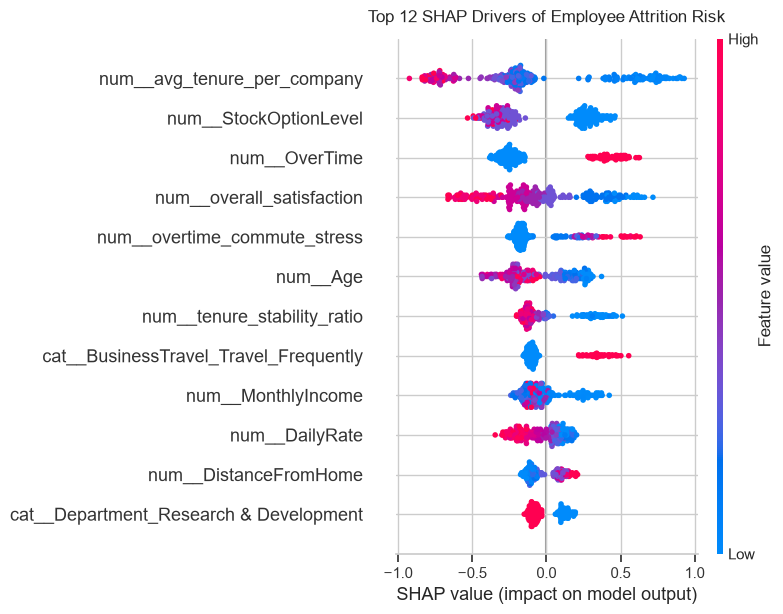

In [7]:
xgb_pipe = models["XGBoost (Depth-Regularized HR Engine)"]

X_test_transformed = xgb_pipe.named_steps["preprocessor"].transform(X_test)
feature_names = xgb_pipe.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(xgb_pipe.named_steps["classifier"])
shap_values = explainer.shap_values(X_test_transformed)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, show=False, max_display=12)
plt.title("Top 12 SHAP Drivers of Employee Attrition Risk", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("outputs/shap_employee_attrition.png", dpi=150)
plt.show()

# Inspect Top Positive & Negative Logistic Regression Coefficients

Top 8 Drivers PUSHING Employees to Leave (Positive Coef):


,Feature,Coefficient (Log-Odds),Odds_Ratio
31,cat__BusinessTravel_Travel_Frequently,1.088,2.970
42,cat__JobRole_Laboratory Technician,0.895,2.446
12,num__OverTime,0.648,1.912
50,cat__MaritalStatus_Single,0.607,1.836
48,cat__JobRole_Sales Representative,0.578,1.783
32,cat__BusinessTravel_Travel_Rarely,0.454,1.574
22,num__YearsSinceLastPromotion,0.387,1.473
34,cat__Department_Sales,0.319,1.375



Top 8 Drivers KEEPING Employees Retained (Negative Coef):


,Feature,Coefficient (Log-Odds),Odds_Ratio
27,num__avg_tenure_per_company,-0.612,0.542
45,cat__JobRole_Research Director,-0.580,0.560
38,cat__EducationField_Other,-0.467,0.627
26,num__tenure_stability_ratio,-0.444,0.641
33,cat__Department_Research & Development,-0.427,0.653
28,num__overall_satisfaction,-0.318,0.727
17,num__TotalWorkingYears,-0.314,0.730
6,num__JobInvolvement,-0.282,0.754


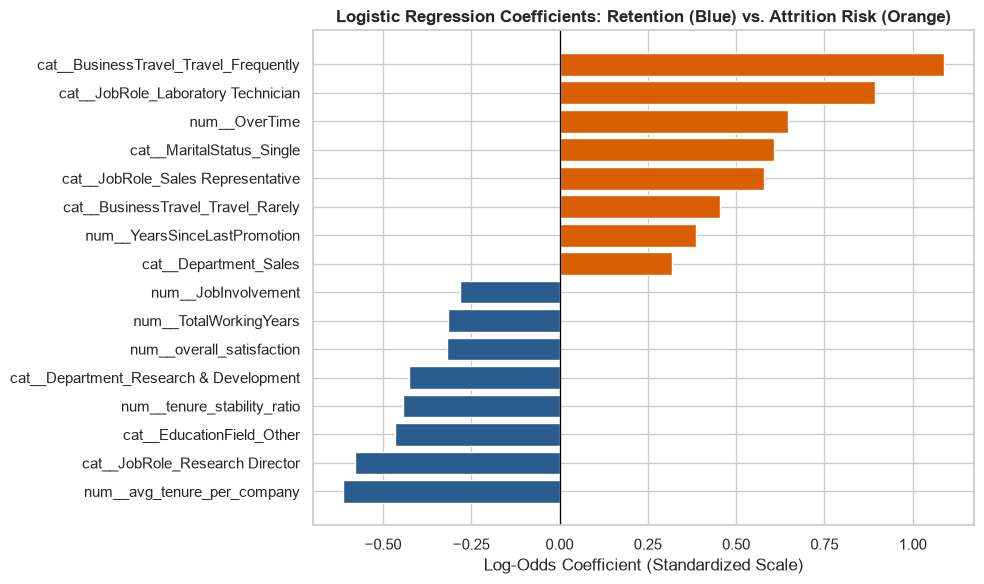

In [8]:
lr_pipe = models["Logistic Regression (L2 Regularized Baseline)"]

# 1. Extract transformed feature names and model weights (log-odds)
feature_names_lr = lr_pipe.named_steps["preprocessor"].get_feature_names_out()
coefs_lr = lr_pipe.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names_lr,
    "Coefficient (Log-Odds)": coefs_lr,
    "Odds_Ratio": np.exp(coefs_lr),
})

top_risk_drivers = coef_df.sort_values(by="Coefficient (Log-Odds)", ascending=False).head(8)
top_retention_drivers = coef_df.sort_values(by="Coefficient (Log-Odds)", ascending=True).head(8)

print("Top 8 Drivers PUSHING Employees to Leave (Positive Coef):")
display(top_risk_drivers.round(3))

print("\nTop 8 Drivers KEEPING Employees Retained (Negative Coef):")
display(top_retention_drivers.round(3))

# 2. Horizontal Bar Chart Comparing Risk vs. Retention Drivers
plot_df = pd.concat([top_risk_drivers, top_retention_drivers]).sort_values(by="Coefficient (Log-Odds)")
colors = ["#2b5c8f" if v < 0 else "#d95f02" for v in plot_df["Coefficient (Log-Odds)"]]

plt.figure(figsize=(10, 6))
plt.barh(plot_df["Feature"], plot_df["Coefficient (Log-Odds)"], color=colors)
plt.axvline(0, color="black", linewidth=0.9)
plt.title("Logistic Regression Coefficients: Retention (Blue) vs. Attrition Risk (Orange)", fontweight="bold")
plt.xlabel("Log-Odds Coefficient (Standardized Scale)")
plt.tight_layout()
plt.savefig("outputs/lr_coefficients.png", dpi=150)
plt.show()